  category                scientific_name  \
0   Mammal  Clethrionomys gapperi gapperi   
1   Mammal                      Bos bison   
2   Mammal                     Bos taurus   
3   Mammal                     Ovis aries   
4   Mammal                 Cervus elaphus   

                                        common_names conservation_status  
0                           Gapper's Red-Backed Vole                 NaN  
1                              American Bison, Bison                 NaN  
2  Aurochs, Aurochs, Domestic Cattle (Feral), Dom...                 NaN  
3  Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)                 NaN  
4                                      Wapiti Or Elk                 NaN  
            scientific_name                            park_name  observations
0        Vicia benghalensis  Great Smoky Mountains National Park            68
1            Neovison vison  Great Smoky Mountains National Park            77
2         Prunus subcordata               

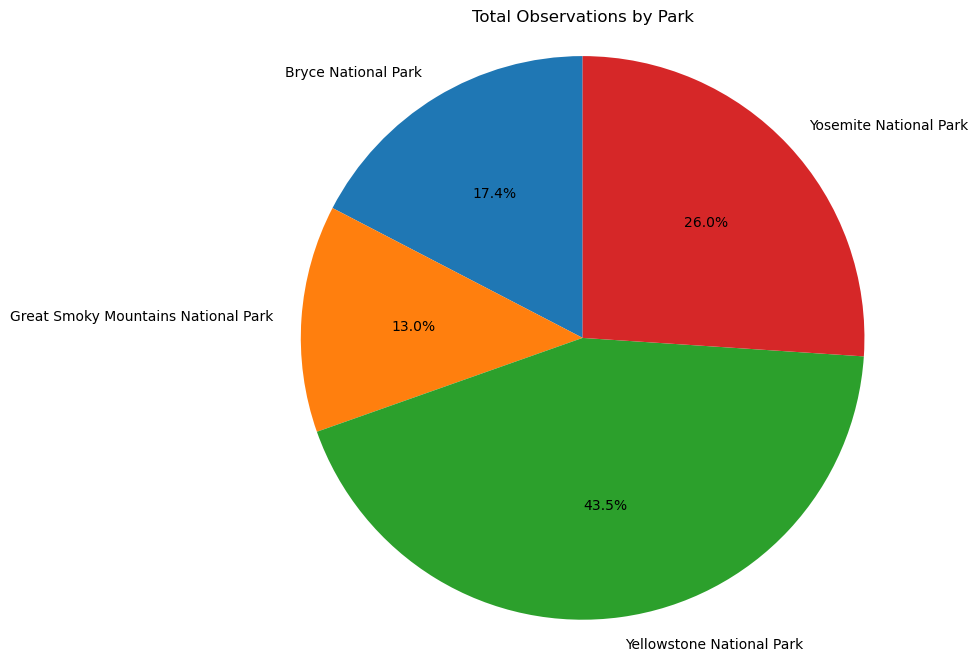

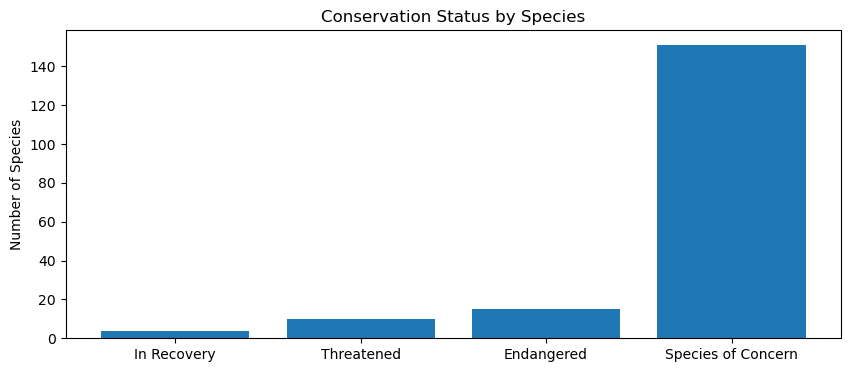

0       Not at Risk
1       Not at Risk
2       Not at Risk
3       Not at Risk
4       Not at Risk
           ...     
5819    Not at Risk
5820    Not at Risk
5821    Not at Risk
5822    Not at Risk
5823    Not at Risk
Name: conservation_status, Length: 5824, dtype: object


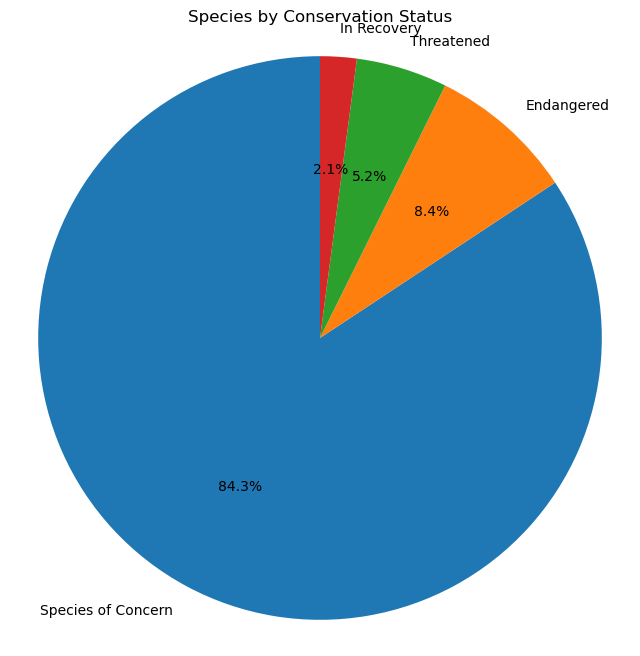

conservation_status  Endangered  In Recovery  Species of Concern  Threatened
category                                                                    
Amphibian                     1            0                   4           2
Bird                          4            3                  72           0
Fish                          3            0                   4           4
Mammal                        7            1                  28           2
Nonvascular Plant             0            0                   5           0
Reptile                       0            0                   5           0
Vascular Plant                1            0                  43           2


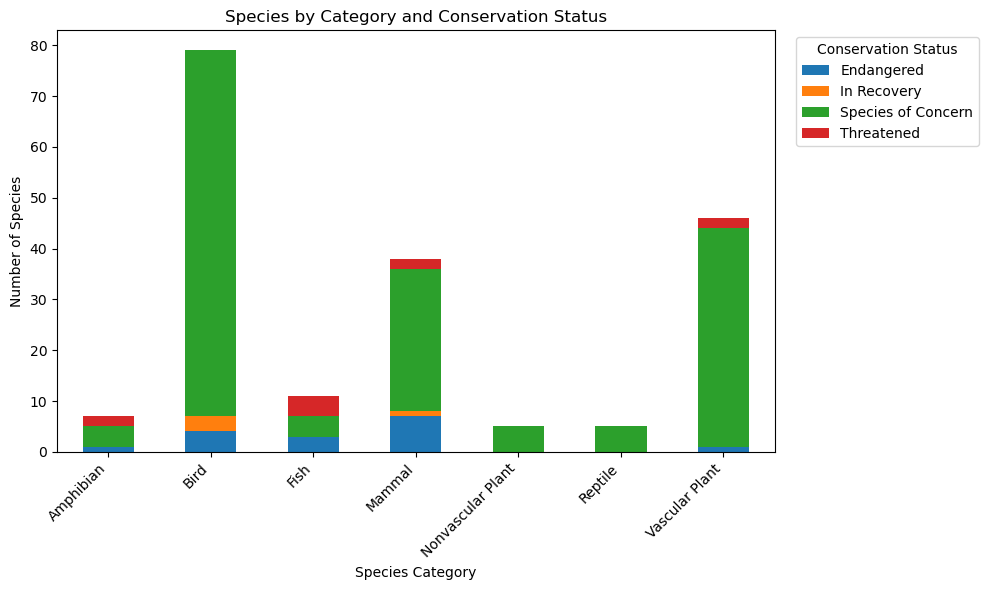

is_protected           category  False  True
0                     Amphibian     72     7
1                          Bird    413    75
2                          Fish    115    11
3                        Mammal    146    30
4             Nonvascular Plant    328     5
5                       Reptile     73     5
6                Vascular Plant   4216    46
            category  not_protected  protected  percent_protected
0          Amphibian             72          7           0.088608
1               Bird            413         75           0.153689
2               Fish            115         11           0.087302
3             Mammal            146         30           0.170455
4  Nonvascular Plant            328          5           0.015015
5            Reptile             73          5           0.064103
6     Vascular Plant           4216         46           0.010793


Chi2ContingencyResult(statistic=np.float64(0.1617014831654557), pvalue=np.float64(0.6875948096661336), dof=1, expected_freq=array([[ 27.8313253, 148.1686747],
       [ 77.1686747, 410.8313253]]))

In [74]:
# Importing libraries and modules
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

#Inspecting both data sets

species = pd.read_csv('species_info.csv')
observations = pd.read_csv('observations_info.csv')

print(species.head(5))
print(observations.head(5))

#Inspecting Observations Data Set

observations.isna().sum()
observations["park_name"].value_counts()
observations.groupby("park_name")["observations"].sum().reset_index() #Calculating totals of observations per park

#Make Pie Chart of number of Observations per Park

totals_obs = observations.groupby("park_name")["observations"].sum()
plt.figure(figsize=(8, 8))
plt.pie(totals_obs, labels=totals.index, autopct="%1.1f%%", startangle=90)
plt.title("Total Observations by Park")
plt.axis("equal")
plt.savefig('totalobservationsbypark.png')
plt.show()

#Inspecting Species Data Set

species.describe()
species.isna().sum()
species.groupby('conservation_status').scientific_name.nunique().reset_index()

species["conservation_status"].isna()
species["conservation_status"].nunique()

#Bar Chart of Total Amount of Species by Conservation Status

protection_counts = species.groupby('conservation_status')\
    .scientific_name.nunique().reset_index()\
    .sort_values(by='scientific_name')

plt.figure(figsize=(10, 4))
ax = plt.subplot()
plt.bar(range(len(protection_counts)),
        protection_counts.scientific_name.values)
ax.set_xticks(range(len(protection_counts)))
ax.set_xticklabels(protection_counts.conservation_status.values)
plt.ylabel('Number of Species')
plt.title('Conservation Status by Species')
plt.savefig('conservationstatusbyspecies.png')
plt.show()

#Create label for NaN values in conservation_status column 
species["conservation_status"] = species["conservation_status"].replace(np.nan, 'Not at Risk')
print(species["conservation_status"])

#Make Pie chart of composition of conservation status
at_risk = species[species["conservation_status"] != "Not at Risk"]

status_counts = at_risk["conservation_status"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90,
)
plt.title("Species by Conservation Status")
plt.axis("equal") 
plt.savefig('speciesbystatus.png')
plt.show()

#Category Exploration Charts

# Excluding species "Not at Risk"
at_risk = species[species["conservation_status"] != "Not at Risk"]

# Table: categories as rows, statuses as columns, counts in the cells
counts = pd.crosstab(at_risk["category"], at_risk["conservation_status"])
print(counts)  #Validation

#Stacked bar chart

counts.plot(kind="bar", stacked=True, figsize=(10, 6))

plt.title("Species by Category and Conservation Status")
plt.xlabel("Species Category")
plt.ylabel("Number of Species")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Conservation Status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig('speciesbycatandstatus.png')
plt.show()


#Inspecting Amount of Species by Category and Status

species['is_protected'] = species.conservation_status != 'Not at Risk'

category_counts = species.groupby(['category', 'is_protected'])\
                         .scientific_name.nunique().reset_index()

category_pivot = category_counts.pivot(columns='is_protected',
                                      index='category',
                                      values='scientific_name')\
                                .reset_index()
print(category_pivot)

#Renaming Columns in Pivot Table
category_pivot.columns = ['category', 'not_protected', 'protected']

#Creting Percent Protected Column
category_pivot['percent_protected'] = category_pivot.protected / \
                                      (category_pivot.protected + category_pivot.not_protected)
print(category_pivot)

#Significance test 

contingency = [[30, 146],
              [75, 413]]

chi2_contingency(contingency)